In [22]:
import matplotlib.pyplot as plt

In [4]:
%uv pip install torch torchaudio datasets scipy librosa

Using Python 3.12.6 environment at: /usr/local
Resolved 77 packages in 395ms
⠙ Preparing packages... (0/16)
⠙ Preparing packages... (0/16)
httpcore2  ------------------------------     0 B/81.47 KiB
⠙ Preparing packages... (0/16)
idna       ------------------------------     0 B/67.95 KiB
httpcore2  ------------------------------     0 B/81.47 KiB
⠙ Preparing packages... (0/16)
pooch      ------------------------------     0 B/65.60 KiB
idna       ------------------------------     0 B/67.95 KiB
httpcore2  ------------------------------     0 B/81.47 KiB
⠙ Preparing packages... (0/16)
truststore ------------------------------     0 B/18.22 KiB
pooch      ------------------------------     0 B/65.60 KiB
idna       ------------------------------     0 B/67.95 KiB
httpcore2  ------------------------------     0 B/81.47 KiB
⠙ Preparing packages... (0/16)
truststore ------------------------------     0 B/18.22 KiB
pooch      ------------------------------     0 B/65.60 KiB
idna       ------

In [5]:
from datasets import load_dataset, Audio

ds = load_dataset("agkphysics/AudioSet", "balanced", split="train", streaming=True)
ds = ds.cast_column("audio", Audio(decode=False))
ex = next(iter(ds))

audio = ex["audio"]
with open(f"{ex['video_id']}.flac", "wb") as f:
    f.write(ex["audio"]["bytes"])
print(ex["video_id"], ex["human_labels"])

README.md:   0%|          | 0.00/5.20k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/38 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/38 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]

--PJHxphWEs ['Speech', 'Gush']


In [6]:
from IPython.display import Audio
Audio("/root/--PJHxphWEs.flac")

48000 sample rate of 2 channels x 10 seconds = 48e4 samples

In [16]:
import torch, torchaudio, torch.nn.functional as F

stereo, sr = torchaudio.load("--PJHxphWEs.flac")
stereo.shape

torch.Size([2, 480000])

we need windows of the audio file: $w[n]$

In [45]:
N = 512
mono = stereo.mean(dim=0)
pad = (-len(mono)) % N
mono = F.pad(mono, (0, pad))
mono = mono.view(-1, N)
mono.shape

torch.Size([938, 512])

short time fourier transform. take a slice, taper edges, and fft that.

stft:
$$X(t,k) = \sum_{n=0}^{N-1} x[n + tH]\, w[n]\, e^{-j2\pi kn/N}$$

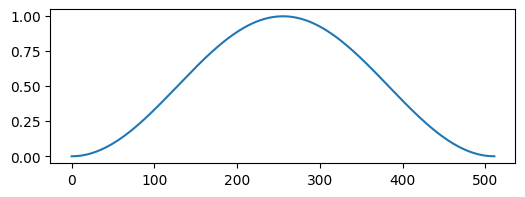

In [46]:
hann_win = 0.5 * (1-torch.cos(2 * torch.pi * torch.arange(N) / (N-1)))
plt.figure(figsize=(6, 2))
plt.plot(hann_win)

$$f_k = k \cdot \frac{\text{sample rate}}{N}$$:  16k * 512 / 48000 ~ 170

In [47]:
(mono * hann_win.unsqueeze(0)).shape

torch.Size([938, 512])

In [48]:
last_64 = []

k = torch.arange(N // 2 + 1, dtype=torch.float32).unsqueeze(1)   # (257, 1)
n = torch.arange(N, dtype=torch.float32).unsqueeze(0)            # (1, 512)


waves = torch.exp(-2j * torch.pi * k * n / N)
conv = (mono * hann_win.unsqueeze(0)).to(torch.complex64)
X = conv @ waves.T
X.shape # (t, k) (timestep, frequency)

torch.Size([938, 257])

power spectrum: $$P[t,k] = |X[t,k]|^2 = \text{Re}^2 + \text{Im}^2$$

In [50]:
P = X.abs()**2
P.shape


torch.Size([938, 257])

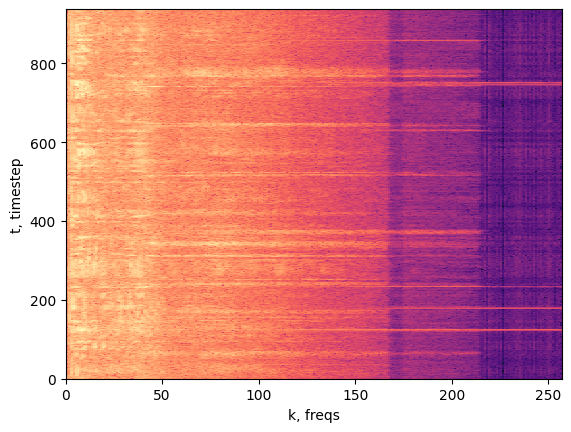

In [51]:
plt.xlabel("k, freqs")
plt.ylabel("t, timestep")
P_db = 10 * torch.log10(P)
plt.pcolormesh(P_db, shading='auto', cmap='magma')

mel filterbank...filter for frequencies better in human ear range. 

$$m = 2595 \log_{10}\!\left(1 + \frac{f}{700}\right)$$

torch.Size([40])
torch.Size([257, 1])


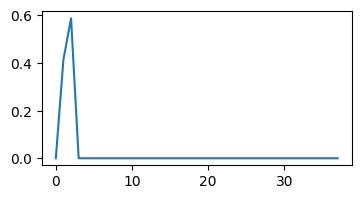

In [69]:
M = 40 # mel bins

def hz2mel(f):  return 2595 * torch.log10(1 + f / 700)
def mel2hz(m):  return 700 * (10 ** (m / 2595) - 1)

fmax = torch.tensor(sr / 2) # nyqiust freq
fmin = torch.tensor(0)

mel_ = torch.linspace(hz2mel(fmin), hz2mel(fmax), M)
hz_ = mel2hz(mel_)
print(hz_)

left, center, right = hz_[:-2], hz_[1:-1], hz_[2:] # (40,)

hz_bins = torch.linspace(fmin, fmax, M)
f = hz_bins.unsqueeze(1) # (257, 1)

# (257, 1) - (40,) = (257, 40)
rising = (f - left) / (center - left)
falling = (right - f) / (right - center)

mel_fb = torch.clamp(torch.minimum(rising, falling), min=0)
# (257, 40)
plt.figure(figsize=(4, 2))
plt.plot(mel_fb[2])

In [70]:
mel = P @ mel_fb
mel_log = torch.log(mel + 1e-10)
mel_log.shape

torch.Size([938, 38])

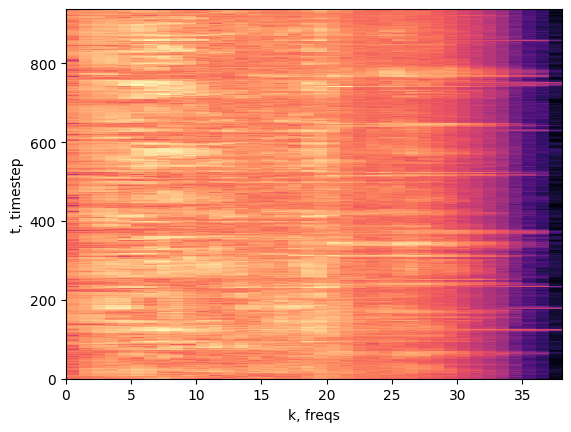

In [71]:
plt.xlabel("k, freqs")
plt.ylabel("t, timestep")
plt.pcolormesh(mel_log, shading='auto', cmap='magma')

This is the shortcut method

In [72]:
import torchaudio, torchaudio.transforms as T
wav, sr = torchaudio.load("--PJHxphWEs.flac")
mel = T.MelSpectrogram(sr, n_fft=257, hop_length=512, n_mels=40)(wav)
log_mel = T.AmplitudeToDB()(mel)
log_mel.shape

/usr/local/lib/python3.12/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/torchaudio/_backend/ffmpeg.py:88: UserWarning: torio.io._streaming_media_decoder.StreamingMediaDecoder has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be r

torch.Size([2, 40, 938])

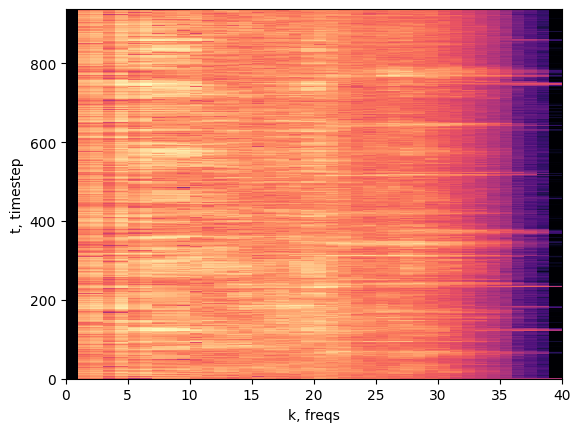

In [74]:
plt.xlabel("k, freqs")
plt.ylabel("t, timestep")
plt.pcolormesh(log_mel.mean(0).T, shading='auto', cmap='magma')